# Lab01 — Phân loại email spam

Notebook giải thích tám bước từ dữ liệu đến kết quả. Các bảng, ma trận và mô hình được đọc từ lần chạy hoàn tất mà models/run_id.txt trỏ tới. Run All không fit lại hoặc ghi đè thực nghiệm tham chiếu. Muốn thử cấu hình mới, sửa YAML và chạy python -m Lab01.src.pipeline, rồi chạy lại notebook.

## 1. Mục tiêu và thiết lập

Phân loại ham (0) và spam (1) bằng ba thuật toán tự cài. Chọn cấu hình và ngưỡng bằng Macro-F1 validation. fit_id định danh một lần học; thử nhiều ngưỡng không tạo lần fit mới.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib,yaml
from scipy.sparse import load_npz
from sklearn.metrics import accuracy_score,f1_score
repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Lab01/src/config.yaml').is_file())
if str(repo) not in sys.path:sys.path.insert(0,str(repo))
from Lab01.src.preprocessing import clean_text
from Lab01.src.tuning import model_scores
from Lab01.src.train import load_training_record
lab=repo/'Lab01'
run=lab/'results'/(lab/'models/run_id.txt').read_text().strip()
manifest=json.loads((run/'run.json').read_text())
assert manifest['status']=='success' and manifest['schema_version']==2
config=yaml.safe_load((run/'config.yaml').read_text())
info=json.loads((run/'models/model_info.json').read_text())
print('Reference run:',run.name)
print(json.dumps(config,ensure_ascii=False,indent=2))


Reference run: 20261119_015148_baseline_tuned
{
  "validation": {
    "fraction": 0.2,
    "seed": 43
  },
  "logistic_regression": {
    "threshold": null,
    "threshold_candidates": [],
    "learning_rate": [
      0.1,
      1.0,
      5.0
    ],
    "n_iterations": [
      1000,
      3000
    ]
  },
  "svm": {
    "candidates": [
      {
        "learning_rate": 0.01,
        "n_iterations": 1000,
        "C": 1
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 3000,
        "C": 1
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 1000,
        "C": 10
      },
      {
        "learning_rate": 0.1,
        "n_iterations": 3000,
        "C": 10
      },
      {
        "learning_rate": 0.01,
        "n_iterations": 1000,
        "C": 50
      },
      {
        "learning_rate": 0.05,
        "n_iterations": 3000,
        "C": 50
      },
      {
        "learning_rate": 0.01,
        "n_iterations": 3000,
        "C": 100
      }
    ]
 

**Kết quả và nhận xét:** cấu hình được in từ bản sao trong run, không suy đoán từ YAML đang chỉnh. Mỗi đối tượng mô hình liên kết với đúng fit_id và vectorizer_id.

## 2. Dữ liệu, làm sạch và loại trùng

Kiểm tra email gốc, ví dụ clean_text và thống kê lọc đã lưu. Việc loại trùng thực hiện trước chia tập.


In [2]:
raw=pd.read_csv(lab/'Data/raw/spam_ham_dataset.csv',keep_default_na=False)
print('Raw rows:',len(raw))
print(raw.label_num.value_counts().to_string())
print('Cleaning example:',clean_text('<b>FREE!!!</b> Click now for the prize.'))
summary=json.loads((run/'preprocessing/summary.json').read_text())
print(json.dumps(summary,indent=2))
cleaned=pd.read_csv(run/'preprocessing/cleaned_raw.csv',keep_default_na=False)
assert not cleaned.text_clean.duplicated().any()
print(cleaned[['email_id','label_num','text_clean']].head().to_string(index=False))


Raw rows: 5171
label_num
0    3672
1    1499
Cleaning example: free click prize
{
  "original_rows": 5171,
  "invalid_rows_removed": 0,
  "empty_rows_removed": 0,
  "duplicates_removed": 287,
  "clean_rows": 4884
}
 email_id  label_num                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

**Kết quả và nhận xét:** so số dòng thô với clean_rows, kiểm tra số dòng loại trùng. Văn bản sạch được giữ cùng ID để truy nguyên.

## 3. Chia tập và TF-IDF

Subtrain học TF-IDF và thuật toán; validation chọn cấu hình/ngưỡng; test đánh giá cuối. Nạp lại TF-IDF đã học, không gọi fit trong notebook.


In [3]:
frames={name:pd.read_csv(run/'preprocessing'/f'{name}_clean.csv',keep_default_na=False)
        for name in ['subtrain','validation','test']}
for left,right in [('subtrain','validation'),('subtrain','test'),('validation','test')]:
    assert not set(frames[left].email_id)&set(frames[right].email_id)
    assert not set(frames[left].text_clean)&set(frames[right].text_clean)
vid=info['models'][0]['vectorizer_id']
feature_dir=run/'preprocessing/tfidf'/vid
vectorizer=joblib.load(run/'models/vectorizers'/f'{vid}.joblib')
matrices={name:load_npz(feature_dir/f'X_{name}.npz') for name in frames}
for name,frame in frames.items():
    difference=vectorizer.transform(frame.text_clean)-matrices[name]
    assert not difference.nnz or np.max(np.abs(difference.data))<1e-12
    np.testing.assert_array_equal(frame.email_id,pd.read_csv(feature_dir/f'y_{name}.csv').email_id)
print(pd.DataFrame([{'split':name,'rows':len(frame),'features':matrices[name].shape[1]} for name,frame in frames.items()]).to_string(index=False))
print('Vectorizer:',vid,'fit split: subtrain')


     split  rows  features
  subtrain  3125     50000
validation   782     50000
      test   977     50000
Vectorizer: tfidf_2e6e4c01802c fit split: subtrain


**Kết quả và nhận xét:** cùng số cột và cùng thứ tự đặc trưng cho cả ba tập. X_subtrain được đặt tên rõ, không nhầm với train ban đầu.

## 4. Baseline trên validation

Đọc ba baseline đã học bằng thông số mặc định. Chưa dùng kết quả test để lựa chọn.


In [4]:
trials=pd.read_csv(run/'tuning/validation_summary.csv')
baseline=trials.loc[trials.variant.eq('baseline')]
print(baseline[['fit_id','model','default_threshold','macro_f1','spam_precision','spam_recall','fp','fn']].to_string(index=False))
for row in baseline.itertuples():
    record=load_training_record(run,row.model,row.fit_id)
    print(row.model,'fit parameters:',record['parameters'],'objective:',record['objective_name'])


  fit_id               model  default_threshold  macro_f1  spam_precision  spam_recall  fp  fn
fit_0001 logistic_regression                0.5  0.412472             0.0     0.000000   0 233
fit_0002                 svm                0.0  0.412472             0.0     0.000000   0 233
fit_0003         naive_bayes                NaN  0.933766             1.0     0.824034   0  41
logistic_regression fit parameters: {'learning_rate': 0.1, 'n_iterations': 1000, 'threshold': 0.5} objective: binary_cross_entropy
svm fit parameters: {'C': 1.0, 'class_weight': None, 'learning_rate': 0.01, 'n_iterations': 1000, 'threshold': 0.0} objective: weighted_hinge_plus_l2
naive_bayes fit parameters: {'alpha': 1.0} objective: None


**Kết quả và nhận xét:** baseline và candidate có fit_id riêng. Naive Bayes không có chuỗi loss theo vòng vì học bằng thống kê trực tiếp.

## 5. Thực nghiệm cấu hình và ngưỡng

Mỗi dòng validation_summary là một lần fit. So default_macro_f1 và selected_macro_f1 trên cùng dòng để tách tác động của việc đổi ngưỡng. Không so điểm loss giữa các thuật toán.


  fit_id               model                                                                                                  parameters  default_macro_f1  selected_macro_f1  fp  fn  selected
fit_0004 logistic_regression                                              {"learning_rate": 0.1, "n_iterations": 1000, "threshold": 0.5}          0.412472           0.962470  20   5     False
fit_0005 logistic_regression                                              {"learning_rate": 0.1, "n_iterations": 3000, "threshold": 0.5}          0.641636           0.966936  18   4     False
fit_0006 logistic_regression                                              {"learning_rate": 1.0, "n_iterations": 1000, "threshold": 0.5}          0.948035           0.980347  11   2     False
fit_0007 logistic_regression                                              {"learning_rate": 1.0, "n_iterations": 3000, "threshold": 0.5}          0.987712           0.992386   4   1     False
fit_0008 logistic_regression            

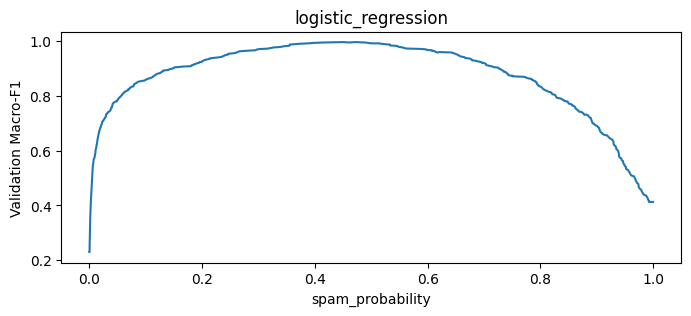

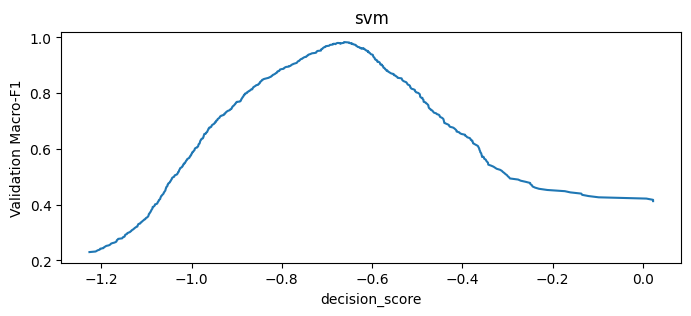

In [5]:
candidates=trials.loc[trials.variant.eq('candidate')]
print(candidates[['fit_id','model','parameters','default_macro_f1','selected_macro_f1','fp','fn','selected']].to_string(index=False))
chosen=json.loads((run/'tuning/selection.json').read_text())
for name,fit_id in chosen['selected_fits'].items():
    path=run/'tuning/threshold_search'/fit_id
    if path.exists():
        sweep=pd.read_csv(path/'thresholds.csv')
        decision=json.loads((path/'selection.json').read_text())
        print(name,'threshold count:',len(sweep),'default:',decision['default']['threshold'],'selected:',decision['selected']['threshold'])
        plt.figure(figsize=(8,3));plt.plot(sweep.threshold,sweep.macro_f1)
        plt.xlabel(decision['score_type']);plt.ylabel('Validation Macro-F1');plt.title(name);plt.show()


**Kết quả và nhận xét:** ngưỡng SVM áp dụng trên điểm quyết định, không phải xác suất. Nếu YAML ép ngưỡng cố định, không đảm bảo ngưỡng đó tốt hơn mặc định.

## 6. Lựa chọn cuối

Giữ nguyên mô hình và TF-IDF đã fit trên subtrain. model_info liên kết đường dẫn mô hình, bộ TF-IDF và lịch sử fit.


In [6]:
entries=[row for row in info['models'] if row['variant']=='tuned']
print(pd.DataFrame(entries)[['model','fit_id','vectorizer_id','threshold','model_path']].to_string(index=False))
selected=trials.loc[trials.selected.eq(True)]
winner=selected.sort_values('macro_f1',ascending=False,kind='stable').iloc[0]['model']
print('Representative model selected on validation:',winner)
for entry in entries:
    assert entry['fit_id']==chosen['selected_fits'][entry['model']]
    assert entry['vectorizer_id']==vid


              model   fit_id      vectorizer_id  threshold                              model_path
logistic_regression fit_0008 tfidf_2e6e4c01802c   0.450945 models/tuned/logistic_regression.joblib
                svm fit_0040 tfidf_2e6e4c01802c  -0.662012                 models/tuned/svm.joblib
        naive_bayes fit_0046 tfidf_2e6e4c01802c        NaN         models/tuned/naive_bayes.joblib
Representative model selected on validation: logistic_regression


**Kết quả và nhận xét:** đại diện chọn từ validation, không dựa trên bảng test. Thay đổi ngưỡng không cập nhật trọng số.

## 7. Đánh giá test và phân tích lỗi

Nạp mô hình đã lưu, dự đoán lại ma trận test, kiểm tra khớp dự đoán và chỉ số. Hiển thị ma trận nhầm lẫn và lỗi của từng mô hình tuned.


              model  variant   fit_id      vectorizer_id split  accuracy  macro_f1  ham_as_spam  spam_as_ham  spam_precision  spam_recall  spam_f1
logistic_regression baseline fit_0001 tfidf_2e6e4c01802c  test  0.702149  0.412508            0          291        0.000000     0.000000 0.000000
                svm baseline fit_0002 tfidf_2e6e4c01802c  test  0.702149  0.412508            0          291        0.000000     0.000000 0.000000
        naive_bayes baseline fit_0003 tfidf_2e6e4c01802c  test  0.942682  0.927334            1           55        0.995781     0.810997 0.893939
logistic_regression    tuned fit_0008 tfidf_2e6e4c01802c  test  0.991812  0.990231            5            3        0.982935     0.989691 0.986301
                svm    tuned fit_0040 tfidf_2e6e4c01802c  test  0.984647  0.981807           12            3        0.960000     0.989691 0.974619
        naive_bayes    tuned fit_0046 tfidf_2e6e4c01802c  test  0.982600  0.979302           11            6        0.

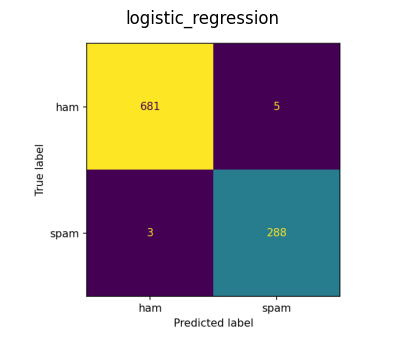

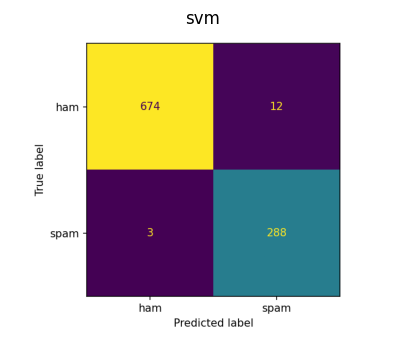

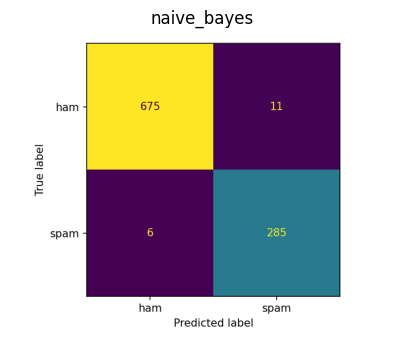

In [7]:
test_summary=pd.read_csv(run/'evaluation/comparison/test_summary.csv')
print(test_summary.to_string(index=False))
for entry in entries:
    model=joblib.load(run/entry['model_path'])
    predicted=model.predict(matrices['test'])
    destination=run/'evaluation'/entry['model']/'tuned'
    saved=pd.read_csv(destination/'predictions.csv')
    np.testing.assert_array_equal(predicted,saved.predicted)
    actual=frames['test'].label_num.to_numpy()
    score=json.loads((destination/'test_metrics.json').read_text())
    assert np.isclose(accuracy_score(actual,predicted),score['accuracy'])
    assert np.isclose(f1_score(actual,predicted,average='macro'),score['macro_f1'])
    plt.figure(figsize=(5,4));plt.imshow(plt.imread(destination/'confusion_matrix.png'));plt.axis('off');plt.title(entry['model']);plt.show()
    print(entry['model'],pd.read_csv(destination/'errors.csv')[['email_id','error_type']].head().to_string(index=False))


**Kết quả và nhận xét:** test chỉ đánh giá sau lựa chọn. Ma trận validation trong tuning và ma trận test trong evaluation không được dùng lẫn nhau.

## 8. Lưu kết quả và kết luận

Kiểm tra chuỗi liên kết từ mô hình đến fit_id, TF-IDF và ngưỡng. Không ghi đầu ra vào run tham chiếu khi đọc notebook.


In [8]:
for entry in info['models']:
    assert (run/entry['model_path']).is_file()
    assert (run/entry['vectorizer_path']).is_file()
    record=load_training_record(run,entry['model'],entry['fit_id'])
    assert record['status']=='success' and record['vectorizer_id']==entry['vectorizer_id']
    print(entry['model'],entry['variant'],'->',entry['fit_id'],'->',entry['vectorizer_id'])
print('Selected fits:',manifest['selected_fits'])
print('Run:',run)
print('No refit; all test predictions reproduced; notebook does not overwrite run artifacts.')


logistic_regression baseline -> fit_0001 -> tfidf_2e6e4c01802c
svm baseline -> fit_0002 -> tfidf_2e6e4c01802c
naive_bayes baseline -> fit_0003 -> tfidf_2e6e4c01802c
logistic_regression tuned -> fit_0008 -> tfidf_2e6e4c01802c
svm tuned -> fit_0040 -> tfidf_2e6e4c01802c
naive_bayes tuned -> fit_0046 -> tfidf_2e6e4c01802c
Selected fits: {'logistic_regression': 'fit_0008', 'svm': 'fit_0040', 'naive_bayes': 'fit_0046'}
Run: E:\ML_Nhóm6\Lab01\results\20261119_015148_baseline_tuned
No refit; all test predictions reproduced; notebook does not overwrite run artifacts.


**Kết luận:** báo cáo chất lượng trên lần chia hiện tại, không khẳng định thuật toán luôn vượt trội. Dữ liệu mới độc lập cần thiết khi đã xem test qua nhiều vòng phát triển.
